In [7]:
import pandas as pd

# چون فایل هدر نداره، اسم ستون‌ها رو خودمون می‌دیم
col_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

df = pd.read_csv('D:\\Programing\\Ai_Engeeniering_course\\Python_files\\IRIS (Hello world to ML) stash\\iris.data', header=None, names=col_names)

print(df.head())
print(df.info())
print(df['species'].value_counts())   # بررسی توازن کلاس‌ها
print(df.describe())

   sepal_length  sepal_width  petal_length  petal_width      species
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 7.9 KB
None
species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64
       sepal_length  sepal_width  petal

C:\Users\hp\AppData\Local\Temp\ipykernel_12544\2409811800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=feat, data=df, ax=ax, palette='Set2')
C:\Users\hp\AppData\Local\Temp\ipykernel_12544\2409811800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=feat, data=df, ax=ax, palette='Set2')
C:\Users\hp\AppData\Local\Temp\ipykernel_12544\2409811800.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='species', y=feat, data=df, ax=ax, palette='Set2')
C:\Users\hp\AppData\Local\Temp\ipykernel_12544\24098118

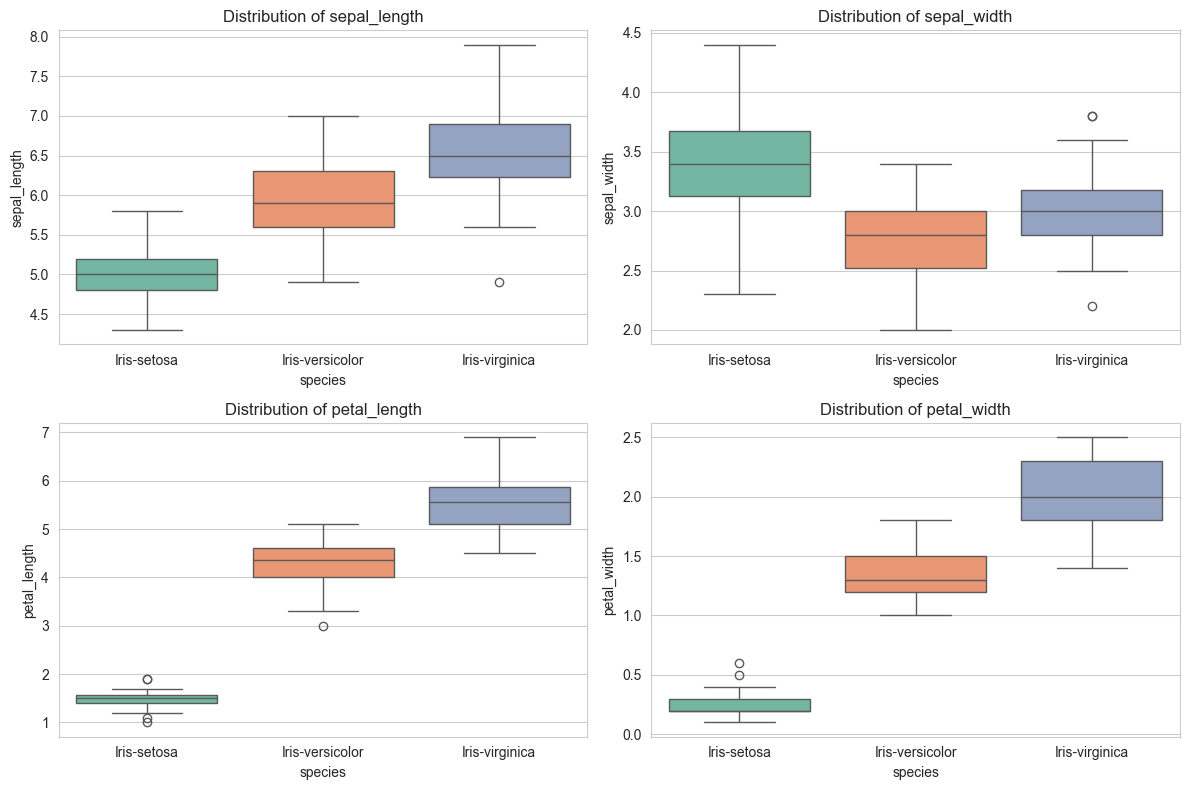

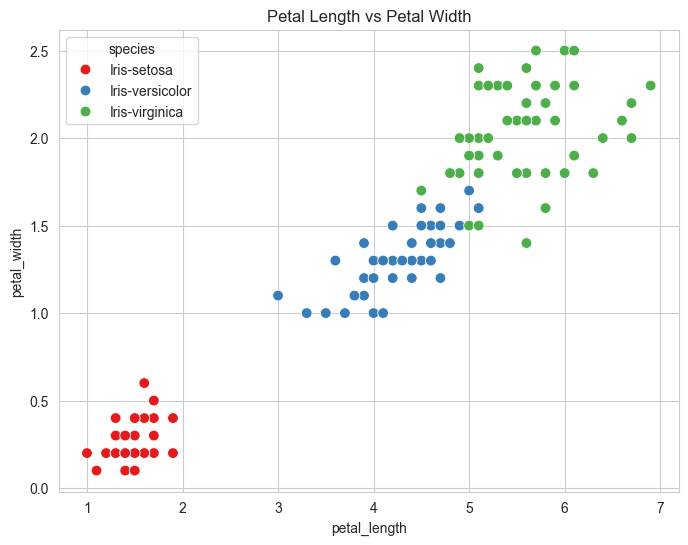

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# تنظیم استایل
sns.set_style("whitegrid")

# 1. Boxplot برای هر ۴ ویژگی
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
features = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

for i, feat in enumerate(features):
    ax = axes[i // 2, i % 2]
    sns.boxplot(x='species', y=feat, data=df, ax=ax, palette='Set2')
    ax.set_title(f'Distribution of {feat}')

plt.tight_layout()
plt.show()

# 2. Scatter Plot: طول گلبرگ در برابر عرض گلبرگ
plt.figure(figsize=(8, 6))
sns.scatterplot(x='petal_length', y='petal_width', hue='species', data=df, palette='Set1', s=60)
plt.title('Petal Length vs Petal Width')
plt.show()


In [9]:
from sklearn.model_selection import train_test_split

# X: چهار ویژگی ورودی
X = df.drop(columns='species')

# y: گونه‌ای که می‌خواهیم پیش‌بینی کنیم
y = df['species']

# تقسیم داده‌ها: 80٪ آموزش، 20٪ آزمون
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("اندازه کل داده:", X.shape)
print("داده آموزشی:", X_train.shape)
print("داده آزمایشی:", X_test.shape)

print("\nتعداد نمونه‌های هر گونه در داده آموزشی:")
print(y_train.value_counts())

print("\nتعداد نمونه‌های هر گونه در داده آزمایشی:")
print(y_test.value_counts())


اندازه کل داده: (150, 4)
داده آموزشی: (120, 4)
داده آزمایشی: (30, 4)

تعداد نمونه‌های هر گونه در داده آموزشی:
species
Iris-setosa        40
Iris-virginica     40
Iris-versicolor    40
Name: count, dtype: int64

تعداد نمونه‌های هر گونه در داده آزمایشی:
species
Iris-setosa        10
Iris-virginica     10
Iris-versicolor    10
Name: count, dtype: int64


In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline

# ساخت یک زنجیره: اول استانداردسازی، بعد مدل KNN
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

# یادگیری از داده‌های آموزشی
knn_model.fit(X_train, y_train)

print("مدل با موفقیت آموزش دید.")


مدل با موفقیت آموزش دید.


In [11]:
# پیش‌بینی گونه برای داده‌های آزمون
y_pred = knn_model.predict(X_test)

# مقایسه چند پیش‌بینی با پاسخ واقعی
comparison = pd.DataFrame({
    "واقعی": y_test,
    "پیش‌بینی مدل": y_pred
})

print(comparison.head(10))


               واقعی     پیش‌بینی مدل
38       Iris-setosa      Iris-setosa
127   Iris-virginica   Iris-virginica
57   Iris-versicolor  Iris-versicolor
93   Iris-versicolor  Iris-versicolor
42       Iris-setosa      Iris-setosa
56   Iris-versicolor  Iris-versicolor
22       Iris-setosa      Iris-setosa
20       Iris-setosa      Iris-setosa
147   Iris-virginica   Iris-virginica
84   Iris-versicolor  Iris-versicolor


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"دقت مدل: {accuracy:.2%}")
print(f"تعداد پیش‌بینی‌های درست: {(y_test == y_pred).sum()} از {len(y_test)}")


دقت مدل: 93.33%
تعداد پیش‌بینی‌های درست: 28 از 30


In [13]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))


                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.83      1.00      0.91        10
 Iris-virginica       1.00      0.80      0.89        10

       accuracy                           0.93        30
      macro avg       0.94      0.93      0.93        30
   weighted avg       0.94      0.93      0.93        30



In [14]:
from sklearn.metrics import confusion_matrix
import pandas as pd

labels = sorted(y.unique())

cm = confusion_matrix(y_test, y_pred, labels=labels)

cm_df = pd.DataFrame(
    cm,
    index=[f"واقعی: {label}" for label in labels],
    columns=[f"پیش‌بینی: {label}" for label in labels]
)

print(cm_df)


                        پیش‌بینی: Iris-setosa  پیش‌بینی: Iris-versicolor  \
واقعی: Iris-setosa                         10                          0   
واقعی: Iris-versicolor                      0                         10   
واقعی: Iris-virginica                       0                          2   

                        پیش‌بینی: Iris-virginica  
واقعی: Iris-setosa                             0  
واقعی: Iris-versicolor                         0  
واقعی: Iris-virginica                          8  
